# Noise Ablation for the Interventional MMD Flow: Injected vs. Additive Noise (CelebA, Female Arm)

The counterpart of the ColorMNIST noise ablation for the CelebA pipeline, where the sampler
is the Riesz energy flow driven by AdamW rather than a fixed-step Euler flow with an IMQ
kernel. Everything except the noise is the configuration of the female-arm notebook.

Two features of this sampler change what noise can do, and are the reason the ablation is
worth repeating here rather than transferring the ColorMNIST conclusions.

**The Riesz kernel has no bandwidth.** For $k(u,v) = -\lVert u - v\rVert$ the gradient is
$-(u - v)/\lVert u - v\rVert$: unit magnitude at every separation. The vanishing-gradient
"dead zone" that motivates noise injection for a bounded kernel cannot arise, so smoothing
the velocity field has no stuck configuration to rescue.

**AdamW rescales every coordinate.** The optimiser divides each coordinate by its own
gradient second-moment estimate, so a perturbation of the point at which the gradient is
read is largely normalised away before it reaches the update. Additive noise is applied to
the particle state *after* the optimiser step and bypasses that normalisation entirely.
The asymmetry between the two mechanisms is therefore larger here than under plain Euler.

In [1]:
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import binary_stats, load_celeba_paper
from data_utils.celeba import to_image_range
from autoencoder_utils import decode_latents, encode_images, load_sd_vae
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import adamw_riesz_flow, constant_noise, halving_noise
from metric_utils import sliced_wasserstein

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. The Two Noise Mechanisms

With $\mathcal F(P) = \tfrac12 \lVert \mu_P - \hat\chi_{\mathrm{DR}}(\pi)\rVert^2$ the flow
objective and $g_n$ the AdamW update built from its gradient, the two updates are

$$
\textbf{injected:}\quad
Y_{n+1} = Y_n - g_n\!\big[\nabla \mathcal F(Y_n + \beta_n u_n)\big],
\qquad
\textbf{additive:}\quad
Y_{n+1} = Y_n - g_n\!\big[\nabla \mathcal F(Y_n)\big] + \beta_n u_n .
$$

**Injected noise** perturbs only where the gradient is read. Because
$\mathbb E_u[\nabla \mathcal F(\cdot + \beta u)] = \nabla(\mathcal F * \varphi_\beta)$, it
smooths the velocity field, leaves the particle state deterministic, and **does not move
the minimiser** — so it requires no annealing for correctness.

**Additive noise** perturbs the particle state itself. This is the diffusion of
(mean-field) Langevin dynamics: it keeps the particle law absolutely continuous, which is
what KL-type finite-particle guarantees require, but it **biases the stationary law** by an
entropy term of order $\beta^2$ relative to the step scale, so $\beta_n$ must be annealed
to zero to remove the bias.

They are not comparable at equal $\beta$: additive noise displaces a particle by $\beta$
per step, while injected noise reaches the update only through the induced change in the
gradient — and here also through AdamW's normalisation. Each mechanism is therefore swept
on its own grid, with $\beta$ in units of the standardised latent coordinates.

## 2. Data, Latents, and Cross-Fitted DR Target

The configuration of the female-arm notebook: the controlled observational sample
($n = 2048$ at $256 \times 256$), frozen SD-VAE latents standardised per coordinate, and
the cross-fitted one-step DR weights on one shared 5-fold split. Both $X$ and $A$ are
binary, so the construction reduces to cell-wise post-stratification and
$\sum_i v_i X_i = 0.300$ is an algebraic check.

In [2]:
TARGET_A = 0
N_ITER = 4000
CACHE = "../../data/celeba_dgp/celeba_paper_256_n2048_nref2000_seed0.pt"
CELEBA_ROOT = "/nfs/ghome/live/danceh/data/celeba"   # machine-local; used only to (re)generate

data = load_celeba_paper(CACHE, root=CELEBA_ROOT, seed=0, image_size=256,
                         n_obs=2048, n_ref=2000, verbose=False)
A = data["A"].view(-1).long()
X = data["X"].view(-1).long()
Y = data["Y"]
Y_ref = data[f"Y{TARGET_A}_ref"]
arm = A == TARGET_A

vae = load_sd_vae(device)
Z = encode_images(vae, Y)
Z_ref = encode_images(vae, Y_ref)
latent_mean = Z.mean(dim=0, keepdim=True)
latent_std = Z.std(dim=0, keepdim=True).clamp_min(1e-3)
to_flow = lambda z: (z - latent_mean) / latent_std
from_flow = lambda p: p * latent_std + latent_mean
Z_std, Z_ref_std = to_flow(Z), to_flow(Z_ref)
print(f"arm a={TARGET_A} size = {int(arm.sum())}   latents {tuple(Z.shape)}")

/nfs/ghome/live/bbozkurt/.conda/envs/torchnn/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


arm a=0 size = 1126   latents (2048, 4096)


In [3]:
n = len(A)
fold_ids = make_crossfit_fold_ids(n, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X.double().unsqueeze(1), A.double(), fold_ids)
w_hat = (A == TARGET_A).double() / (e1 if TARGET_A == 1 else 1.0 - e1)

K_x = (X[:, None] == X[None, :]).double()
K_a = (A[:, None] == A[None, :]).double()
K_a_target = (A == TARGET_A).double()[:, None].expand(n, n).contiguous()
K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_std[train, 0].double().cpu(), seed=0)
v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids,
                                fold_lambdas).float().to(device)

arm_indices = torch.nonzero(arm).ravel()
M = min(1024, len(arm_indices))
pick = arm_indices[torch.randperm(len(arm_indices),
                                  generator=torch.Generator().manual_seed(SEED))[:M]]
initial_particles = Z_std[pick].clone()
print(f"DR weights: sum(v) = {v_dr.sum():.3f}   sum|v| = {v_dr.abs().sum():.3f}   "
      f"sum(v X) = {(v_dr.cpu() * X.float()).sum():.3f}")
print(f"M = {M} particles")

DR weights: sum(v) = 1.000   sum|v| = 1.000   sum(v X) = 0.300
M = 1024 particles


## 3. The Ablation

Every run differs only in `noise_mode`, the scale $\beta_0$, and the schedule
(**constant**, or **halving** every 667 iterations). Runs are scored in latent space by the
sliced Wasserstein-2 distance between the particle cloud and the encoded held-out
references — the same yardstick as the flow trajectory in the method notebook, and cheap
enough to sweep. Pixel-space metrics, which require decoding, are computed afterwards for
the baseline and the best setting of each mechanism.

In [4]:
SCHEDULES = {"const": constant_noise,
             "halving": lambda beta: halving_noise(beta, halve_every=N_ITER // 6)}
GRIDS = {"injected": [0.01, 0.03, 0.1, 0.3],
         "additive": [0.0003, 0.001, 0.003, 0.01]}


def run_flow(mode, beta, schedule):
    torch.manual_seed(1)
    particles, history = adamw_riesz_flow(
        initial_particles.clone(), Z_std, target_weights=v_dr, sliced=False,
        n_iterations=N_ITER, learning_rate=0.001, warmup_steps=100, lr_schedule="cosine",
        noise_schedule=None if beta == 0 else SCHEDULES[schedule](beta), noise_mode=mode,
        generator=torch.Generator(device=device).manual_seed(SEED + 3), verbose=False)
    return dict(latent_sw2=sliced_wasserstein(particles, Z_ref_std, p=2, seed=0).item(),
                loss=history["loss"][-1], mode=mode, beta=beta, schedule=schedule,
                transport=float((particles - initial_particles).norm(dim=1).mean()),
                particles=particles)


results = [dict(run_flow("injected", 0.0, "const"), tag="no noise")]
for mode in ("injected", "additive"):
    for schedule in SCHEDULES:
        for beta in GRIDS[mode]:
            results.append(dict(run_flow(mode, beta, schedule),
                                tag=f"{mode} b={beta:g} {schedule}"))
latent_floor = sliced_wasserstein(Z_ref_std[:1000], Z_ref_std[1000:], p=2, seed=0).item()
print(f"{len(results)} flow runs completed   latent reference-split floor {latent_floor:.4f}")

17 flow runs completed   latent reference-split floor 0.0769


## 4. Results

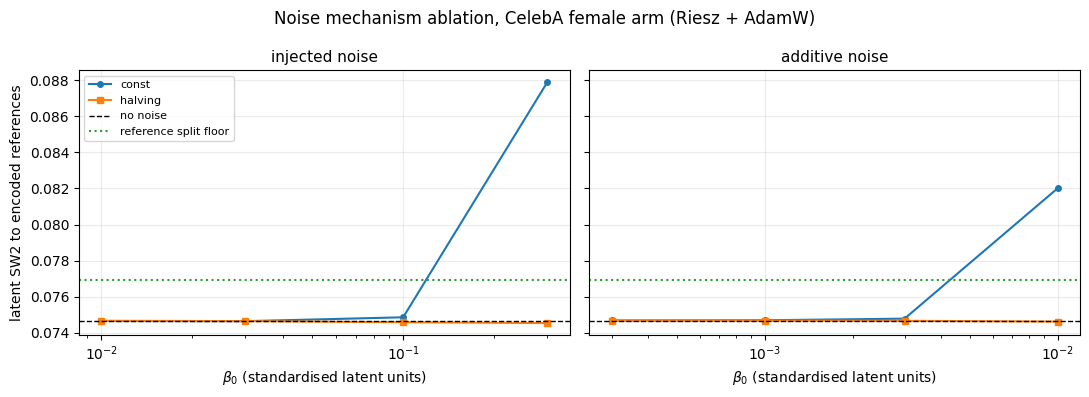

In [5]:
baseline = results[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, mode in zip(axes, ("injected", "additive")):
    for schedule, marker in zip(SCHEDULES, ("o", "s")):
        pts = [r for r in results if r["mode"] == mode and r["schedule"] == schedule
               and r["beta"] > 0]
        ax.plot([r["beta"] for r in pts], [r["latent_sw2"] for r in pts],
                marker=marker, ms=4, label=schedule)
    ax.axhline(baseline["latent_sw2"], ls="--", c="k", lw=1, label="no noise")
    ax.axhline(latent_floor, ls=":", c="tab:green", lw=1.5, label="reference split floor")
    ax.set_xscale("log")
    ax.set_xlabel(r"$\beta_0$ (standardised latent units)")
    ax.set_title(f"{mode} noise", fontsize=11)
    ax.grid(alpha=0.25)
axes[0].set_ylabel("latent SW2 to encoded references")
axes[0].legend(fontsize=8)
fig.suptitle("Noise mechanism ablation, CelebA female arm (Riesz + AdamW)", fontsize=12)
fig.tight_layout()
plt.show()

In [6]:
best = {mode: min((r for r in results if r["mode"] == mode and r["beta"] > 0),
                  key=lambda r: r["latent_sw2"])
        for mode in ("injected", "additive")}
print(f"{'run':30s} {'latent SW2':>11s} {'Riesz loss':>11s} {'transport':>10s}")
for r in (baseline, best["injected"], best["additive"]):
    print(f"{r['tag']:30s} {r['latent_sw2']:11.4f} {r['loss']:11.4f} {r['transport']:10.2f}")
print(f"{'reference split floor':30s} {latent_floor:11.4f}")

run                             latent SW2  Riesz loss  transport
no noise                            0.0747     63.6414       4.52
injected b=0.3 halving              0.0745     63.6486       4.33
additive b=0.01 halving             0.0746     63.6410       4.66
reference split floor               0.0769


## 5. How Each Mechanism Acts

The transport column separates the mechanisms mechanically: additive noise inflates the
distance particles travel in proportion to $\beta$, whereas injected noise barely changes
it, because AdamW normalises the perturbed gradient before it reaches the update.

The loss column carries a warning that is specific to an *estimated* target. The Riesz loss
is the objective the sampler minimises, $\lVert \mu_Q - \hat\chi_{\mathrm{DR}}\rVert^2$, but
$\hat\chi_{\mathrm{DR}}$ is an estimate: settings that reach a lower objective can produce
worse samples, and both mechanisms exhibit this inversion at their largest scales. The
distance to the held-out references, not the objective, is the quantity to read.

In [7]:
print(f"{'run':30s} {'latent SW2':>11s} {'Riesz loss':>11s} {'transport':>10s}")
for r in sorted((r for r in results if r["schedule"] == "const" or r["tag"] == "no noise"),
                key=lambda r: (r["mode"], r["beta"])):
    print(f"{r['tag']:30s} {r['latent_sw2']:11.4f} {r['loss']:11.4f} {r['transport']:10.2f}")

run                             latent SW2  Riesz loss  transport
additive b=0.0003 const             0.0747     63.6389       4.72
additive b=0.001 const              0.0747     63.6305       5.43
additive b=0.003 const              0.0748     63.5586       8.54
additive b=0.01 const               0.0820     62.3971      27.44
no noise                            0.0747     63.6414       4.52
injected b=0.01 const               0.0747     63.6404       4.50
injected b=0.03 const               0.0746     63.6375       4.50
injected b=0.1 const                0.0749     63.6236       4.70
injected b=0.3 const                0.0879     63.6162       6.08


## 6. Pixel-Space Metrics

The best setting of each mechanism, decoded and scored against the 2000 held-out reference
images following the protocol of Dance et al. (2026): SW2 (base) is the observed arm, the
flow's source, and SW2 (target) the flowed sample.

In [8]:
flatten = lambda images: images.reshape(images.shape[0], -1)


def pixel_scores(images):
    return (sliced_wasserstein(flatten(images), flatten(Y_ref), p=2, seed=0).item(),
            sliced_wasserstein(flatten(images), flatten(Y_ref), p=1, seed=0).item())


decoded = {}
for r in (baseline, best["injected"], best["additive"]):
    with torch.no_grad():
        decoded[r["tag"]] = decode_latents(vae, from_flow(r["particles"]), 256)
print(f"{'sample':30s} {'SW2':>8s} {'SW1':>8s}")
sw2, sw1 = pixel_scores(Y[arm_indices])
print(f"{'observed arm (base)':30s} {sw2:8.4f} {sw1:8.4f}")
for tag, images in decoded.items():
    sw2, sw1 = pixel_scores(images)
    print(f"{tag + ' (target)':30s} {sw2:8.4f} {sw1:8.4f}")
sw2_f, sw1_f = pixel_scores(Y_ref[:1000]) if False else (
    sliced_wasserstein(flatten(Y_ref[:1000]), flatten(Y_ref[1000:]), p=2, seed=0).item(),
    sliced_wasserstein(flatten(Y_ref[:1000]), flatten(Y_ref[1000:]), p=1, seed=0).item())
print(f"{'reference 1000/1000 floor':30s} {sw2_f:8.4f} {sw1_f:8.4f}")

sample                              SW2      SW1


observed arm (base)              0.0521   0.0395


no noise (target)                0.0376   0.0261


injected b=0.3 halving (target)   0.0379   0.0263


additive b=0.01 halving (target)   0.0377   0.0262


reference 1000/1000 floor        0.0399   0.0276


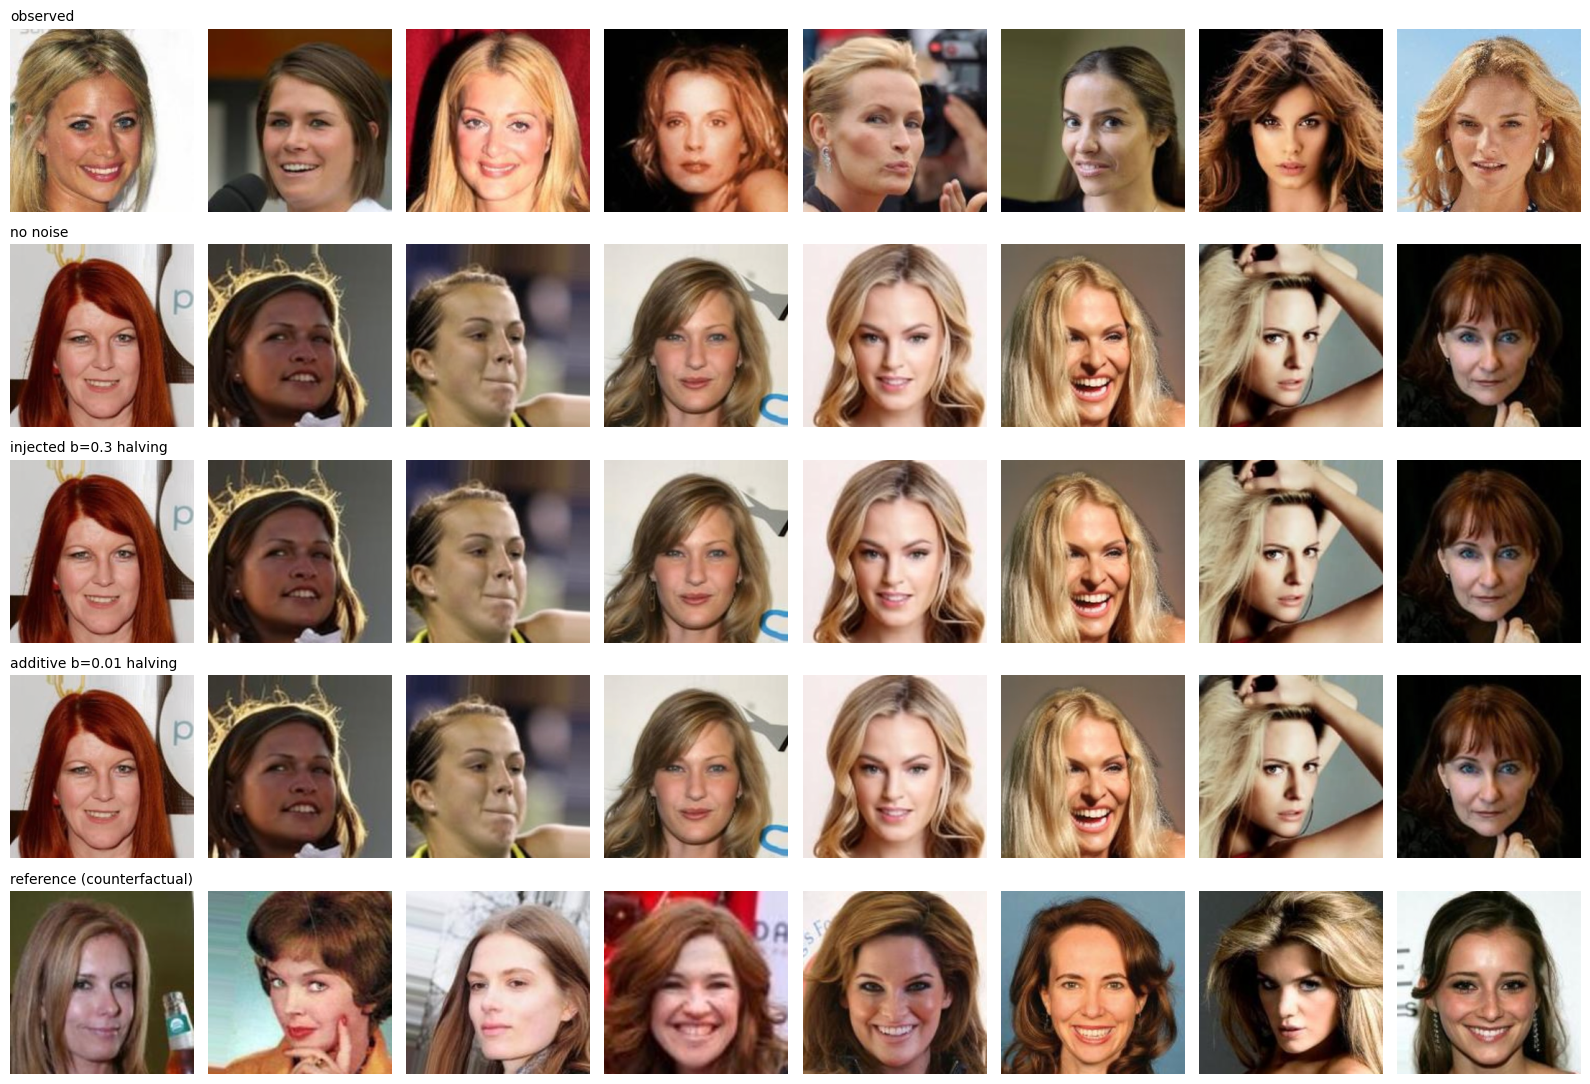

In [9]:
n_show, idx = 8, 24
ref_pick = torch.randperm(len(Y_ref), generator=torch.Generator().manual_seed(2))[:n_show]
panels = [("observed", Y[arm_indices[idx:idx + n_show]])]
panels += [(tag, images[idx:idx + n_show]) for tag, images in decoded.items()]
panels.append(("reference (counterfactual)", Y_ref[ref_pick]))
fig, axes = plt.subplots(len(panels), n_show, figsize=(2.0 * n_show, 2.2 * len(panels)))
for row, (title, images) in enumerate(panels):
    for column in range(n_show):
        axes[row, column].imshow(to_image_range(images[column]).permute(1, 2, 0).numpy())
        axes[row, column].axis("off")
    axes[row, 0].set_title(title, fontsize=10, loc="left")
fig.tight_layout()
plt.show()

## Summary

- **Neither mechanism changes the result.** The best injected setting ($0.0745$) and the
  best additive setting ($0.0746$) are indistinguishable from the noise-free flow
  ($0.0747$) in latent space, and the pixel-space table agrees ($0.0379$ and $0.0377$ vs
  $0.0376$; base $0.0521$, floor $0.0399$). The noise-free flow already sits below the
  latent reference-split floor, so there is nothing for noise to repair.
- **Injected noise is close to inert for this sampler**, far more so than for the
  fixed-step IMQ flow on ColorMNIST: scales up to $\beta = 0.1$ move the latent
  distance by at most $0.0001$. Two reasons compound. The Riesz kernel has no bandwidth —
  its gradient has unit magnitude at every separation, so the vanishing-gradient
  configuration that noise injection exists to escape cannot arise — and AdamW normalises
  each coordinate by its gradient statistics, damping what remains. Only $\beta = 0.3$ at
  a constant schedule bites ($0.0879$), and annealing removes even that.
- **Additive noise separates itself by transport**, as it did on ColorMNIST: mean
  transport climbs $4.5 \to 5.4 \to 8.5 \to 27.4$ across its grid while the latent distance
  stays flat and then degrades ($0.0820$ at $\beta = 0.01$). Its useful scale is roughly
  thirty times smaller than the injected one, so the two must never share a grid.
- **Both mechanisms invert loss against quality at their largest scales.** Additive noise
  at $\beta = 0.01$ reaches a markedly *lower* Riesz loss than the noise-free run
  ($62.40$ vs $63.64$) while scoring *worse* against the held-out references ($0.0820$ vs
  $0.0747$); injected noise at $\beta = 0.3$ does the same ($63.6162$ vs $63.6414$, and
  $0.0879$ vs $0.0747$). The objective is built from an *estimated* embedding, so driving
  it lower can mean fitting estimation noise. This is the concrete reason these notebooks
  report distance to held-out reference samples rather than the optimisation objective.
- **Recommendation.** Leave noise off for the Riesz/AdamW sampler. If it is wanted for a
  theoretical reason, use injected noise with an annealing schedule, which is bias-free and
  costs nothing here; adopt additive noise only when the absolute-continuity guarantees of
  the Langevin analysis are specifically required, and then anneal it to zero.